In [245]:
import os
import SimpleITK as sitk
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import binary_dilation, binary_fill_holes, grey_dilation
from scipy.ndimage import binary_erosion, binary_closing, grey_closing
from scipy.ndimage import binary_opening, gaussian_filter, label
from skimage.filters import frangi
from skimage.morphology import remove_small_objects

file_name = os.listdir(r"Dataset\DICOMs")[1]
dicom_folder_dir = r"Dataset\DICOMs\\" + file_name
nifit_file_dir = r"Dataset\NIFTIs\\" + file_name + ".nii" + '.gz'

file_name

'002'

In [246]:
dicom_folder_dir, os.listdir(dicom_folder_dir)[:5]

('Dataset\\DICOMs\\\\002',
 ['Image (0001).dcm',
  'Image (0002).dcm',
  'Image (0003).dcm',
  'Image (0004).dcm',
  'Image (0005).dcm'])

In [247]:
# convert entire dicom series to nifti including metadata and compress it
def convert_to_nifti(dicom_dir, nifti_dir):
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(dicom_dir)
    reader.SetFileNames(dicom_names)
    image = reader.Execute()
    sitk.WriteImage(image, nifti_dir)

# convert_to_nifti(dicom_folder_dir, nifit_file_dir)

In [248]:
_sitk_image = sitk.ReadImage(nifit_file_dir)
_sitk_image.GetSize(), _sitk_image.GetSpacing()

((512, 512, 2000), (0.8066409826278687, 0.8066409826278687, 0.625))

In [249]:
line_points = {
    '001': {
        "z_below_fat": 690,
        "z_above_fat": 980,
        "y_below_fat": 170,
        "seed": [950, 110, 300],
        'vein_slide': 203
    },
    
    '002': {
        "z_below_fat": 840,
        "z_above_fat": 1120,
        "y_below_fat": 252,
        "seed": [1056, 185, 185],
        'vein_slide': 1056 - 840
    },
    
    'HGUCEGXI': {
        "z_below_fat": 175,
        "z_above_fat": 220,
        "y_below_fat": 200,
        "seed": [200, 120, 290],
        'vein_slide': 36
    }
}[file_name]

_seed = line_points['seed']
vein_slide = line_points['vein_slide']

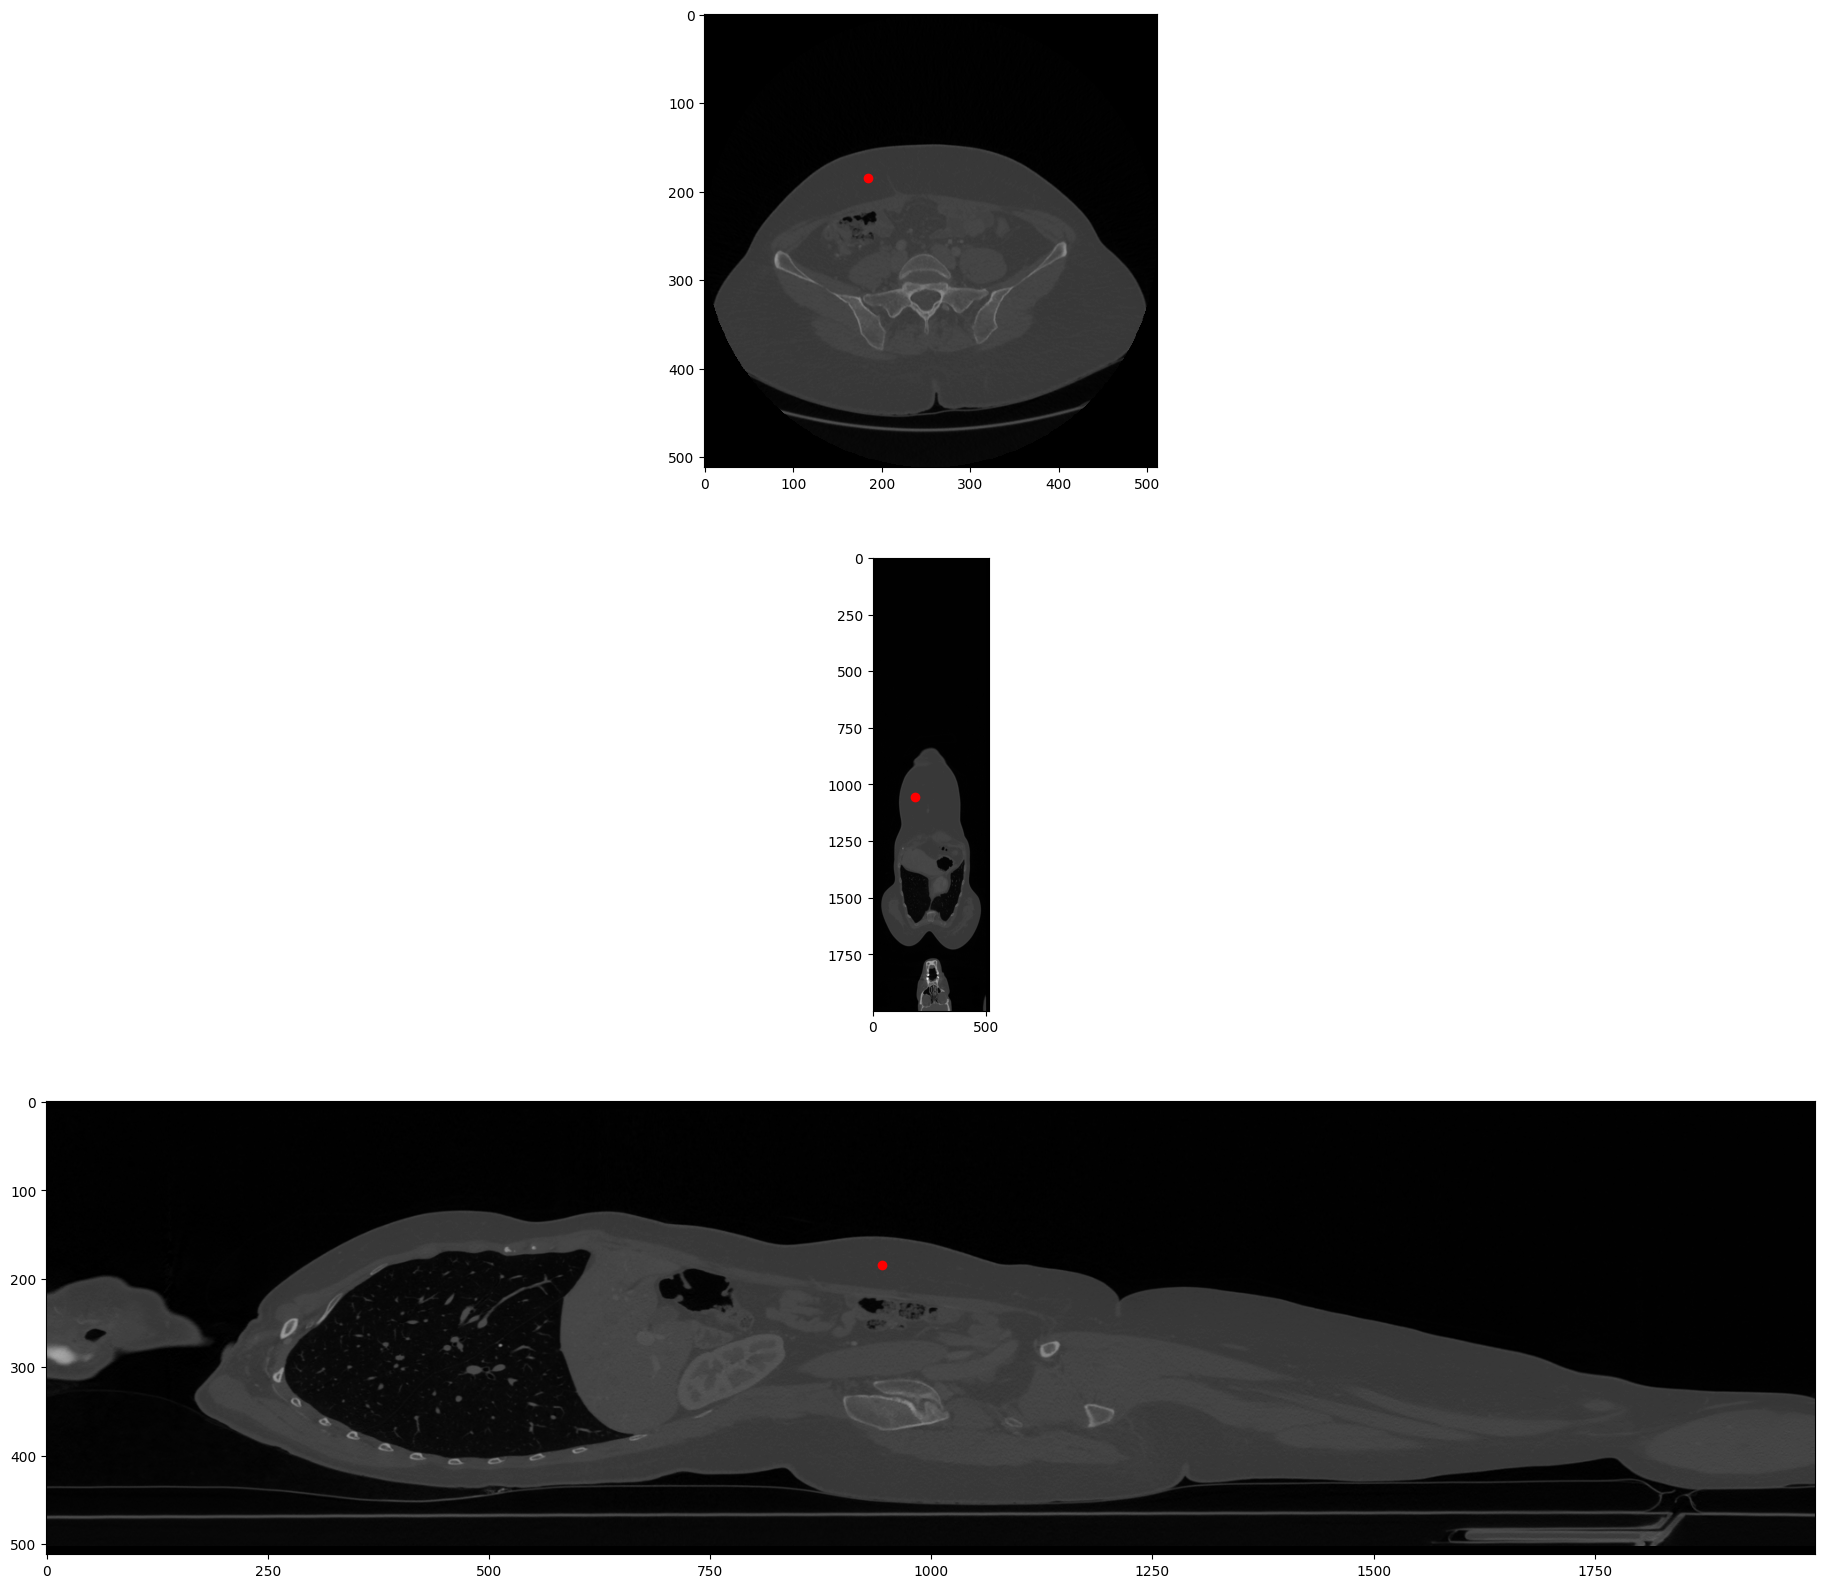

In [250]:
def show_slice(img, mask, seed):
    fig, ax = plt.subplots(3, 1, figsize=(30, 20))
    mask = mask.astype(np.uint8) if mask is not None else None

    ax[0].imshow(img[seed[0], :, :], cmap='gray', vmin=-1024, vmax=3071)
    if mask is not None:
        ax[0].imshow(mask[seed[0], :, :], cmap='Greens', vmin=0, vmax=1, alpha=mask[seed[0], :, :] * 0.5)
    ax[0].scatter(seed[2], seed[1], c='r')

    ax[1].imshow(img[:, seed[1], :], cmap='gray', vmin=-1024, vmax=3071)
    if mask is not None:
        ax[1].imshow(mask[:, seed[1], :], cmap='Greens', vmin=0, vmax=1, alpha=mask[:, seed[1], :] * 0.5)
    ax[1].scatter(seed[2], seed[0], c='r')

    ax[2].imshow(np.rot90(img[:, :, seed[2]], -1), cmap='gray', vmin=-1024, vmax=3071)
    if mask is not None:
        ax[2].imshow(np.rot90(mask[:, :, seed[2]], -1), cmap='Greens', vmin=0, vmax=1,
                     alpha=np.rot90(mask[:, :, seed[2]], -1) * 0.5)
    ax[2].scatter(img.shape[0] - seed[0], seed[1], c='r')

    plt.show()


show_slice(sitk.GetArrayFromImage(_sitk_image), None, _seed)

Segment the fat area by first creating a very puffed fat area. this is achieved by using a very restrictive threshold for the fat area which gives a very uneven and noisy mask for fat. then we use dilation to puff up the fat area which results in a mask thats covering the fat and a bit of surrounding area.
We will then create a second mask which is later intersected with the first mask to get a more accurate fat area.
this second area is created by using a less restrictive threshold for the fat area which gives an accurate mask for the fat area but also includes some of the organ areas. we then remove the organ areas by using the first mask via intersection.

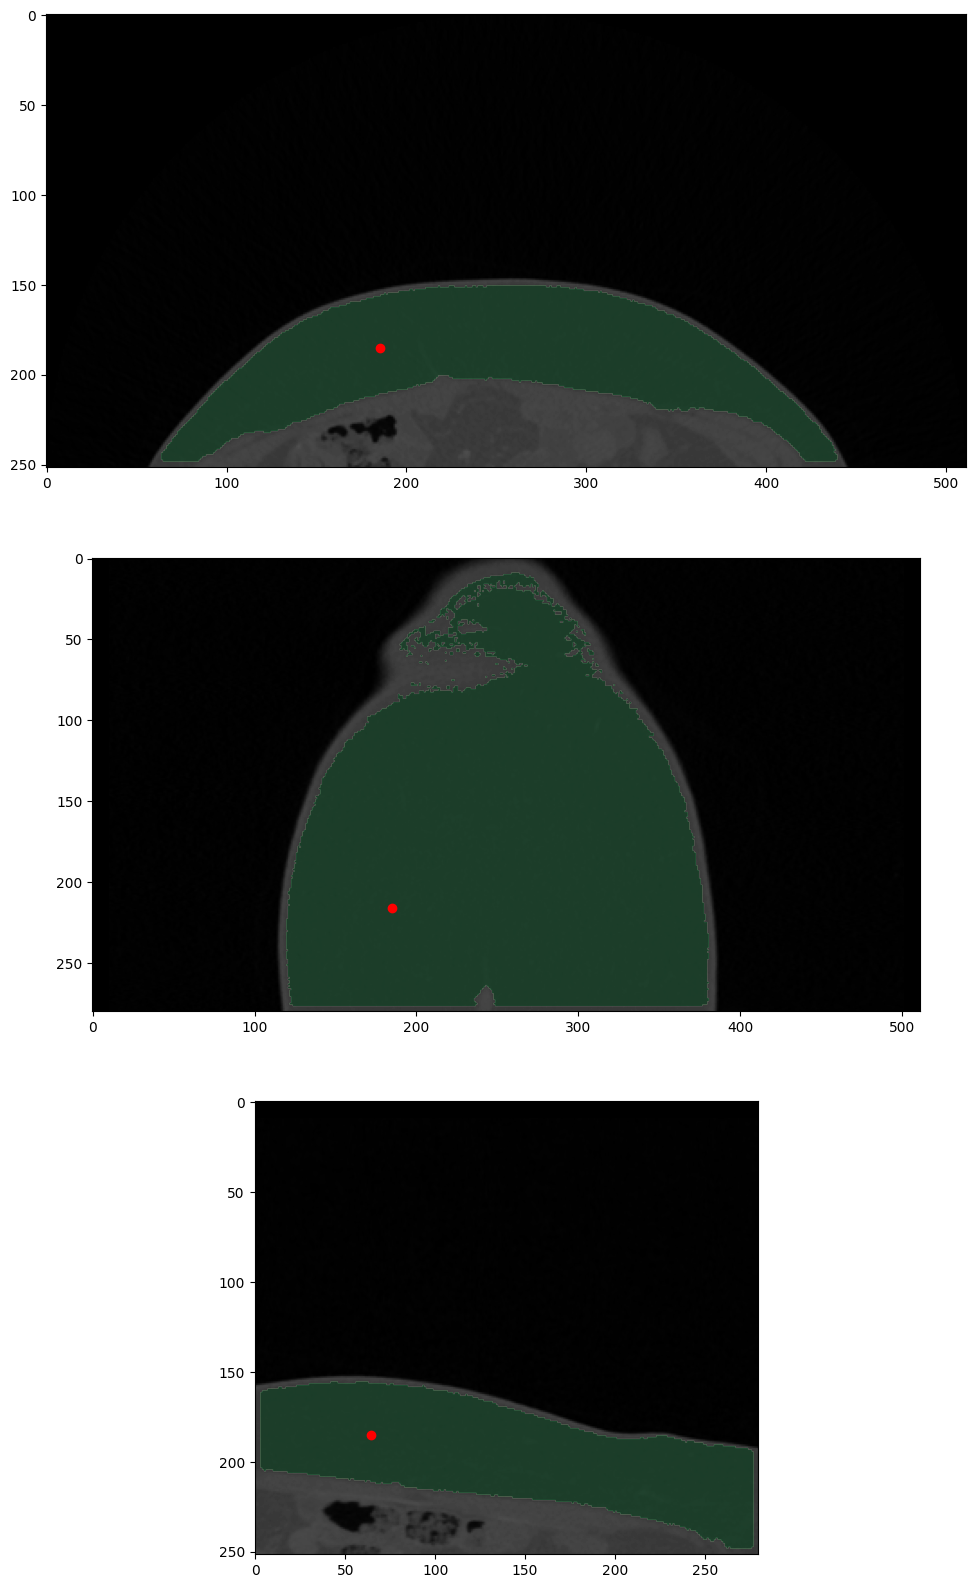

In [251]:
def remove_small_objects_windowed(mask, window_size=3, min_size=[1500, 600, 600]):
    k = window_size
    mask = mask.astype(bool)
    for element in range(3):
        slicing_array = [slice(None), slice(None), slice(None)]
        for i in range(0, mask.shape[element], k):
            for j in range(0, k, k // 2):
                slicing_array[element] = slice(i, i + k)
                # todo: replace remove_small_objects with a function that keeps the labels
                mask[*slicing_array] = remove_small_objects(mask[*slicing_array], min_size=min_size[element])

    return mask


def fat_region_growing(sitk_image, seed, lower=-150, upper=-50):
    return sitk.GetArrayFromImage(sitk.ConnectedThreshold(sitk_image, seedList=[seed[::-1]], lower=lower, upper=upper))


def get_larger_than_fat_area(sitk_image, seed):
    mask = fat_region_growing(sitk_image, seed)

    mask = gaussian_filter(mask, 0.1).astype(np.uint8)

    mask = binary_opening(mask, iterations=2).astype(np.uint8)
    mask = binary_erosion(mask, iterations=1)
    mask = remove_small_objects_windowed(mask, window_size=3, min_size=[2500, 1000, 1000])
    mask = binary_dilation(mask, iterations=5)
    mask = binary_erosion(mask, iterations=1)

    return mask.astype(bool)


def get_fat_and_organ_area(sitk_image, seed):
    mask = fat_region_growing(sitk_image, seed, lower=-160, upper=-40)
    mask = binary_fill_holes(mask)

    return mask.astype(bool)


def get_fat_area(sitk_image, seed):
    fat_dilated = get_larger_than_fat_area(sitk_image, seed)
    fat_and_organ = get_fat_and_organ_area(sitk_image, seed)
    mask = fat_and_organ * fat_dilated

    mask = binary_opening(mask, iterations=1).astype(np.uint8)
    mask = gaussian_filter(mask, 0.1).astype(np.uint8)
    mask = remove_small_objects_windowed(mask, window_size=3, min_size=[2500, 1000, 1000])
    mask = 1 - remove_small_objects_windowed(1 - mask, window_size=3, min_size=[2500, 1000, 1000])

    mask = binary_closing(mask, iterations=2)
    mask = binary_opening(mask, iterations=2)
    mask = gaussian_filter(mask, 0.1).astype(np.uint8)
    mask = binary_fill_holes(mask)

    return mask.astype(bool)


def crop_image(_sitk_image, seed, line_points):
    seed = list(seed)
    seed[0] -= line_points["z_below_fat"]

    sitk_image = _sitk_image
    img = sitk.GetArrayFromImage(sitk_image)
    img = img[line_points["z_below_fat"]:line_points["z_above_fat"], :line_points["y_below_fat"], :]

    img = gaussian_filter(img, 0.1)

    sitk_image = sitk.GetImageFromArray(img)
    sitk_image.SetSpacing(_sitk_image.GetSpacing())

    return sitk_image, seed


sitk_image, seed = crop_image(_sitk_image, _seed, line_points)
img = sitk.GetArrayFromImage(sitk_image)

mask = get_fat_area(sitk_image, seed)
mask = binary_erosion(mask, iterations=1)

show_slice(img, mask, (vein_slide, seed[1], seed[2]))

we will normalize the mask area of the image to be between 0 and 1 but a bit more dynamic by using the 99.9th percentile as the max value to remove outliers and the 10th percentile as the min value to remove possible background pixels that are in the mask area.

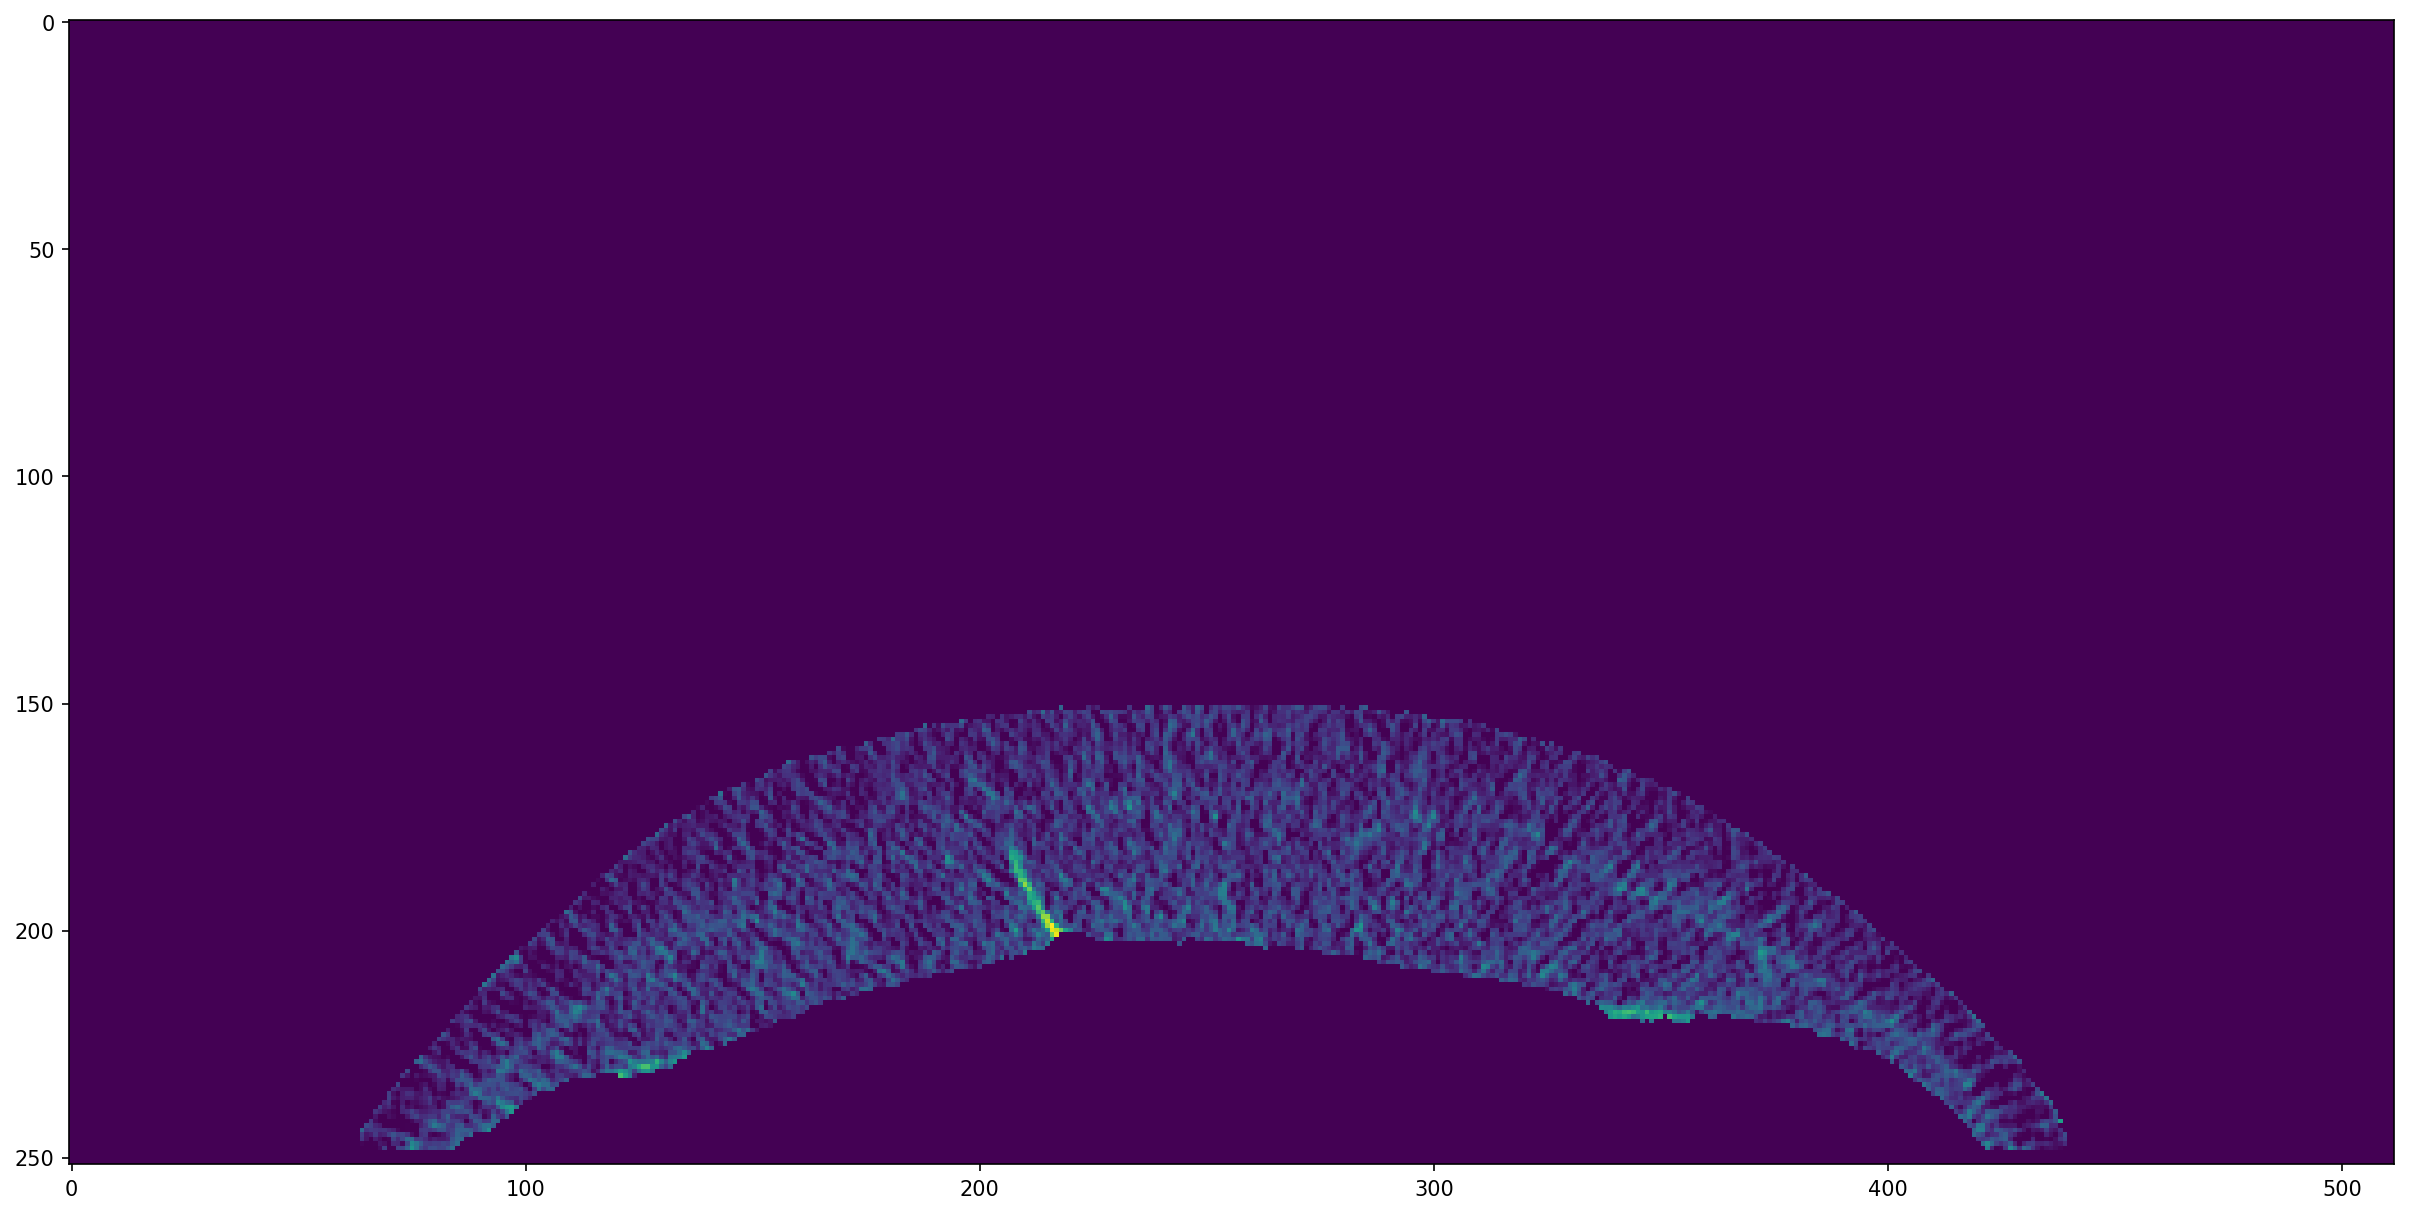

In [252]:
img_balanced = (img + 10000) * mask - 10000

max_value, min_value = np.percentile(img_balanced[mask.astype(bool)], [99.9, 10])
img_balanced = np.clip(img_balanced, min_value, max_value)

img_balanced = (img_balanced - min_value) / (max_value - min_value)

#todo: use a larger, dynamic window size instead of +-3
roi_slide = 3
img_balanced = img_balanced[vein_slide - roi_slide:vein_slide + roi_slide]
img_balanced = gaussian_filter(img_balanced, 0.1)

plt.figure(figsize=(20, 15), dpi=150)
plt.imshow(img_balanced[roi_slide])

run frangi filter on the image to get the vein like structures. we will then normalize the image to be between 0 and 1 but a bit more dynamic similar to before.

In [253]:
# Apply the Frangi filter with adjusted parameters
frangi_slice = frangi(
    img_balanced,
    # scale_range=(1, 2),  # More sensitive to different scales
    # scale_step=1,  # More fine-grained scale steps
    # beta=1.0,  # More sensitive to line-like structures
    # gamma=4,  # Less background suppression for more sensitivity
    black_ridges=False  # Assuming bright ridges on dark background
)

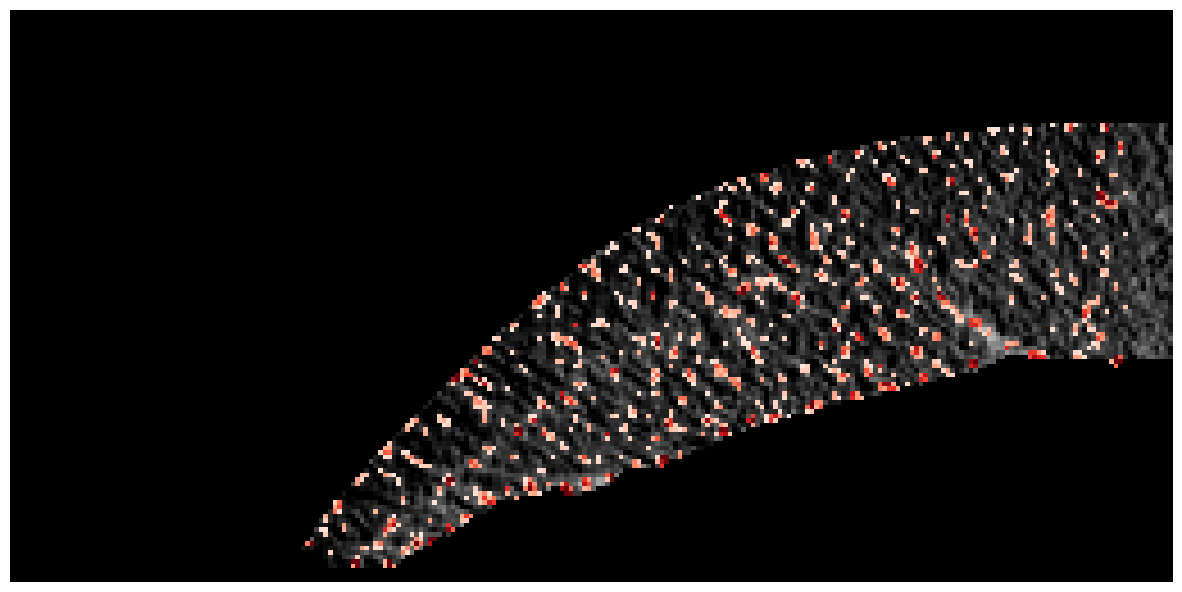

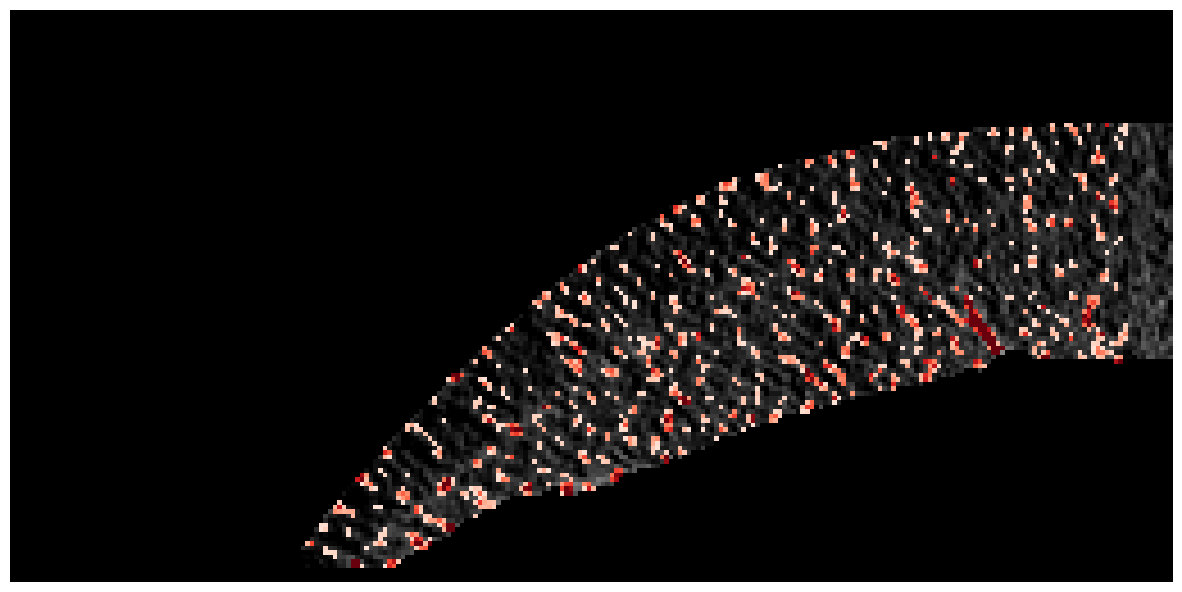

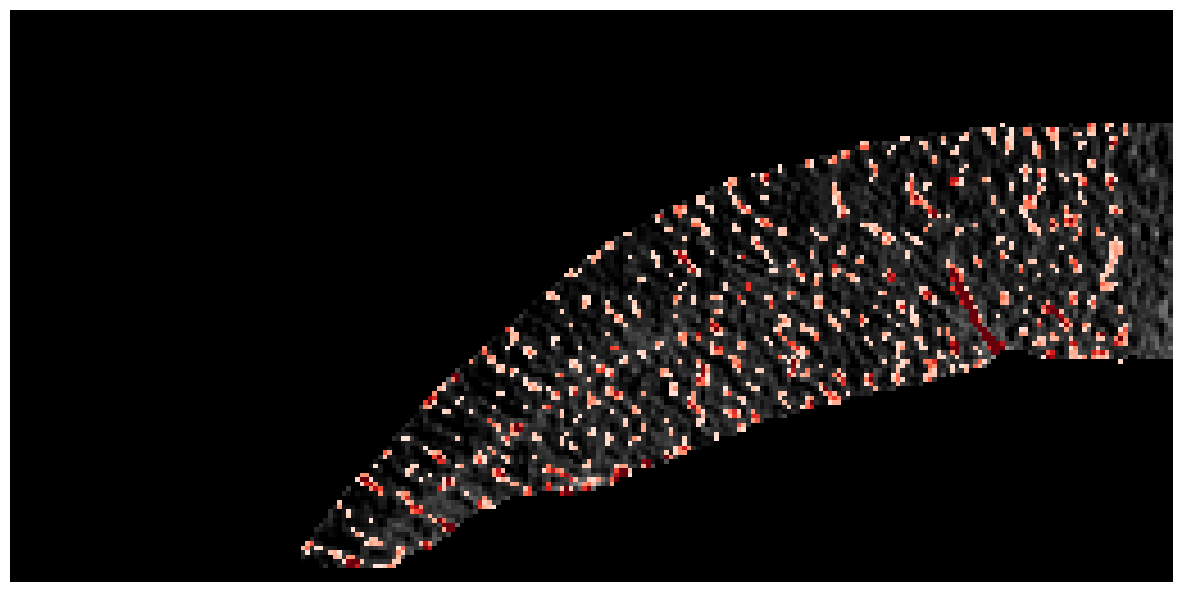

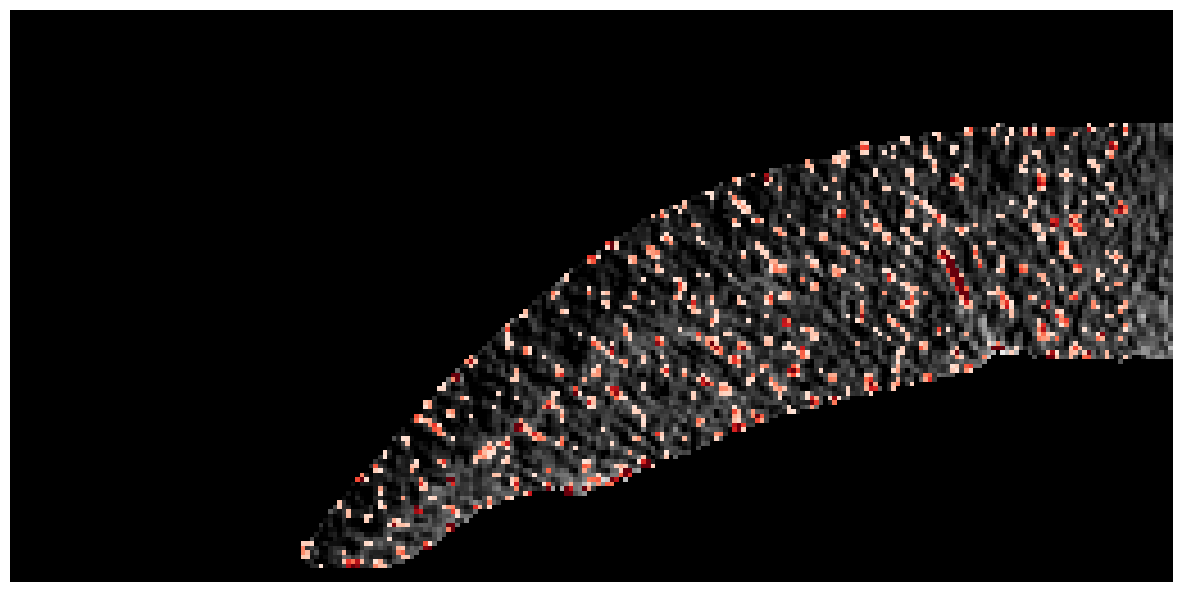

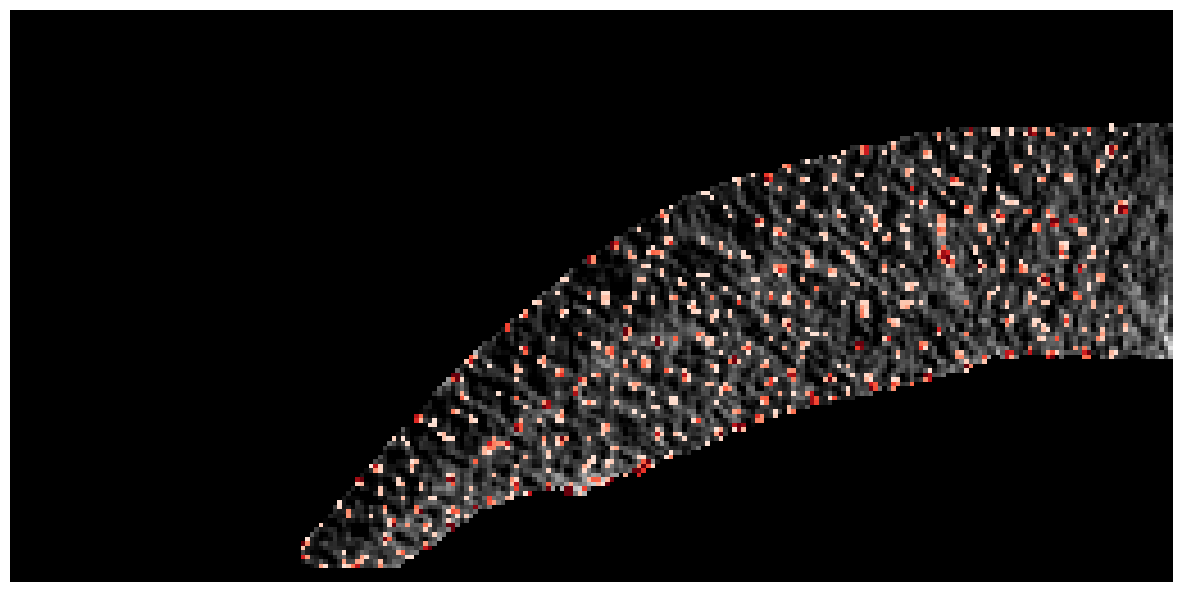

In [254]:
normlized_frangi = frangi_slice.copy()
normlized_frangi = np.clip(normlized_frangi,
                           *np.percentile(normlized_frangi[normlized_frangi > 0], [15, 99.8]))
normlized_frangi /= np.max(normlized_frangi)
normlized_frangi[normlized_frangi < 0.1] = 0
normlized_frangi[:, :, normlized_frangi.shape[2] // 2 - 10:normlized_frangi.shape[2] // 2 + 10] = 0

for i in np.arange(-2, 2 + 1, 1):
    plt.figure(figsize=(15, 10), dpi=100)
    temp = [roi_slide + i, slice(len(img[0]) // 2, len(img[0])), slice(0, len(img[0][0]) // 2)]
    plt.imshow(img_balanced[*temp], cmap="gray")
    plt.imshow(normlized_frangi[*temp], cmap='Reds', alpha=(normlized_frangi[*temp] > 0).astype(float))
    plt.axis('off')
    plt.show()

the veins we are looking for are by nature going from inside to outside, (vertical-ish).
So we run a slide a window over the image and remove objects that dont have much size in a vertical-ish window
Since the veins are not perfectly vertical along the y axis, so its better to replace this 
rect. box-shaped-window with an angled window to better fit the shape of the fat

In [255]:
def remove_small_objects_windowed_via_counting(_mask, window_size=3, min_size=[1500, 600, 600], min_count=4):
    mask = _mask > 0
    count_img = mask.copy().astype(int)
    k = window_size
    for element in range(3):
        slicing_array = [slice(None), slice(None), slice(None)]
        for i in range(0, mask.shape[element], k):
            for j in range(0, k, k // 2):
                slicing_array[element] = slice(i, i + k)
                # todo: replace remove_small_objects with a function that keeps the labels
                count_img[*slicing_array] += remove_small_objects(mask[*slicing_array], min_size=min_size[element])

    count_img[count_img < min_count] = 0
    return (count_img > 0) * _mask

# todo: replace rect. box shaped window with a with a angled window to better fit the shape of the fat
filtered_frangi = normlized_frangi.copy()

filtered_frangi = remove_small_objects_windowed_via_counting(
    filtered_frangi, window_size=4, min_size=[100, 8, 25], min_count=4)

filtered_frangi = grey_closing(filtered_frangi, size=(2, 2, 2))
filtered_frangi = remove_small_objects_windowed_via_counting(
    filtered_frangi, window_size=4, min_size=[75, 10, 55], min_count=5)

filtered_frangi = remove_small_objects_windowed_via_counting(
    filtered_frangi, window_size=5, min_size=[100, 15, 20], min_count=5)

temp = grey_dilation(filtered_frangi, size=(2, 2, 2))
temp = remove_small_objects_windowed(temp, window_size=5, min_size=[250, 18, 65])
filtered_frangi *= temp

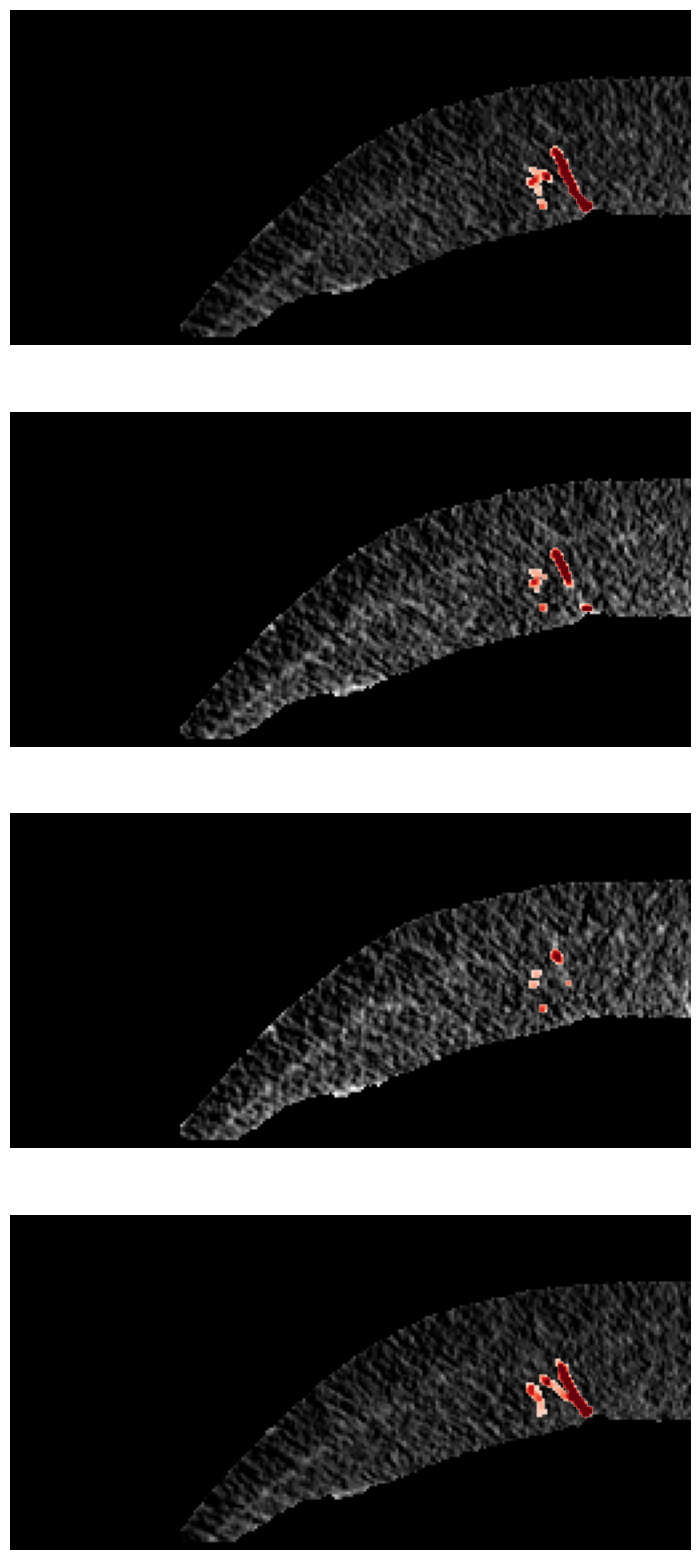

In [256]:
label_matrix, _ = label(normlized_frangi>0)
to_keep_labels = np.unique(label_matrix[filtered_frangi>0])[1:]
label_matrix = np.isin(label_matrix, to_keep_labels)
final_frangi = grey_dilation(normlized_frangi * label_matrix, size=(2, 2, 2))

fig, ax = plt.subplots(4, 1, figsize=(30, 20), dpi=100)
for i in np.arange(-2, 2 + 1, 1):
    temp = [roi_slide + i, slice(len(img[0]) // 2, len(img[0])), slice(0, len(img[0][0]) // 2)]
    ax[i].imshow(img_balanced[*temp], cmap="gray")
    ax[i].imshow(final_frangi[*temp], cmap='Reds', alpha=(final_frangi[*temp] > 0).astype(float))
    ax[i].axis('off')
plt.show()